# HW4 — Cats vs Dogs with CNNs and Transfer Learning

This notebook uses the public Google MLCC cats-vs-dogs dataset as a substitute for the unavailable course archive.

In [1]:
from pathlib import Path
import copy, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models


SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_ROOT = Path("./cats_and_dogs_filtered")
OUT = Path("results")
OUT.mkdir(exist_ok = True)
IMG_SIZE = 150
BATCH_SIZE = 32

device(type='cuda')

## 1. Data preparation

The supplied Google dataset has `train` and `validation` folders. We split the validation folder into validation and test subsets so that the test set remains separate during training.

In [2]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([.485,.456,.406], [.229,.224,.225]),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([.485,.456,.406], [.229,.224,.225]),
])
train_dir = DATA_ROOT / "train"
validation_dir = DATA_ROOT / "validation"
train_ds = datasets.ImageFolder(train_dir, transform=train_transform)
holdout = datasets.ImageFolder(validation_dir, transform=eval_transform)
n_val = len(holdout) // 2
val_ds, test_ds = random_split(holdout, [n_val, len(holdout)-n_val], generator=torch.Generator().manual_seed(SEED))
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
dataset_summary = pd.DataFrame({"split": ["train", "validation", "test"], "images": [len(train_ds), len(val_ds), len(test_ds)]}).set_index("split")
dataset_summary


,images
split,
train,2000
validation,500
test,500


In [3]:
def run_epoch(model, loader, criterion, optimizer = None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0
    correct = 0
    total = 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images, labels = images.to(device), labels.float().to(device)
            logits = model(images).squeeze(1)
            loss = criterion(logits, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            correct += ((torch.sigmoid(logits)>=.5) == labels.bool()).sum().item()
            total += len(labels)
    return total_loss / total, correct / total


def fit(model, epochs = 5, lr = 1e-3):
    model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.AdamW(model.parameters(), lr = lr, weight_decay = 1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best = copy.deepcopy(model.state_dict())
    best_acc = 0
    epochs_without_improvement = 0
    for epoch in range(epochs):
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        for key, value in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
            history[key].append(value)
        scheduler.step(va_acc)
        if va_acc > best_acc:
            best_acc = va_acc
            epochs_without_improvement = 0
            best = copy.deepcopy(model.state_dict())
        else:
            epochs_without_improvement += 1
        if epochs_without_improvement >= 6:
            break
    model.load_state_dict(best)
    return model, history


def find_best_threshold(model, loader):
    model.eval()
    probabilities, targets = [], []
    with torch.no_grad():
        for images, labels in loader:
            probabilities.extend(torch.sigmoid(model(images.to(device)).squeeze(1)).cpu().numpy())
            targets.extend(labels.numpy())
    thresholds = np.linspace(0.20, 0.80, 61)
    accuracies = [np.mean((np.array(probabilities) >= threshold) == np.array(targets)) for threshold in thresholds]
    return float(thresholds[int(np.argmax(accuracies))])


def evaluate_model(model, threshold=0.5):
    model.eval()
    losses, predictions, targets = [], [], []
    criterion = nn.BCEWithLogitsLoss()
    with torch.no_grad():
        for images, labels in test_loader:
            logits = model(images.to(device)).squeeze(1)
            losses.append(criterion(logits, labels.float().to(device)).item() * len(labels))
            predictions.extend((torch.sigmoid(logits).cpu().numpy() >= threshold))
            targets.extend(labels.numpy())
    return {"test_loss": sum(losses) / len(test_loader.dataset), "test_accuracy": np.mean(np.array(predictions) == np.array(targets)), "threshold": threshold}


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set(title = f"{title}: loss", xlabel="epoch")
    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="validation")
    axes[1].set(title = f"{title}: accuracy", xlabel="epoch")
    [ax.legend() for ax in axes]
    plt.tight_layout()
    plt.show()
    return fig

## 2. Custom CNN with three convolutional layers

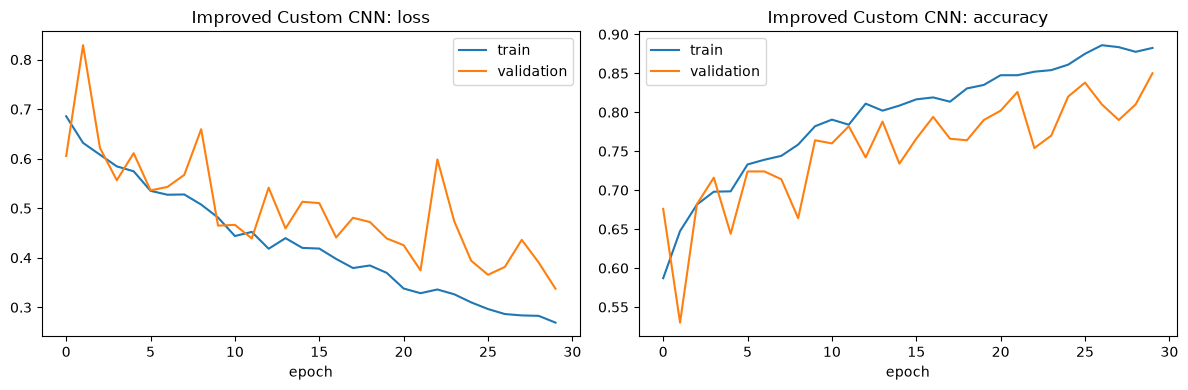

,test_loss,test_accuracy,threshold
Improved Custom CNN,0.416996,0.806,0.47


In [4]:
class CNN3(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True), nn.MaxPool2d(2),
            nn.Conv2d(256, 384, 3, padding=1), nn.BatchNorm2d(384), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.35), nn.Linear(384, 1))

    def forward(self, x):
        return self.classifier(self.features(x))


cnn_model, cnn_history = fit(CNN3(), epochs=30, lr=5e-4)
cnn_threshold = find_best_threshold(cnn_model, val_loader)
cnn_score = evaluate_model(cnn_model, threshold=cnn_threshold)
plot_history(cnn_history, "Improved Custom CNN")
pd.DataFrame([cnn_score], index=["Improved Custom CNN"])


## 3. VGG16 transfer learning

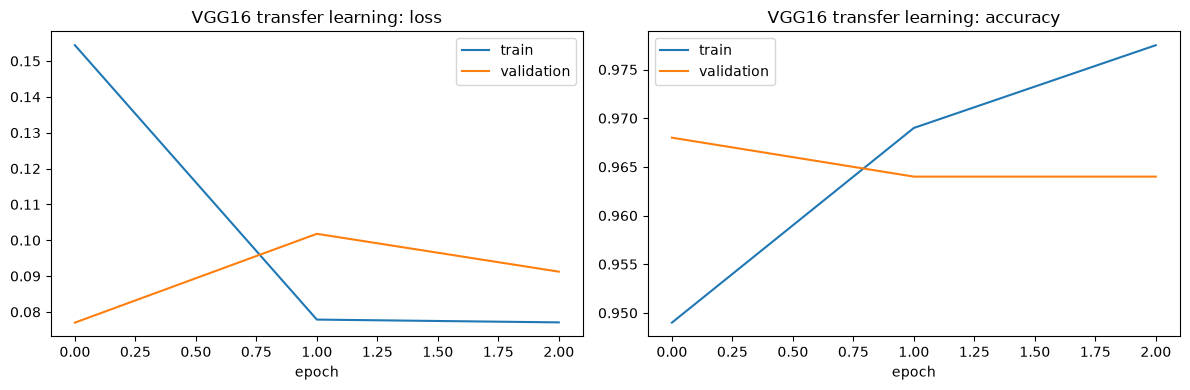

,test_loss,test_accuracy,threshold
VGG16,0.078671,0.964,0.5


In [5]:
def make_vgg():
    weights = models.VGG16_Weights.DEFAULT
    model = models.vgg16(weights = weights)
    for parameter in model.features.parameters():
        parameter.requires_grad = False
    model.classifier[6] = nn.Linear(model.classifier[6].in_features, 1)
    return model


vgg_model, vgg_history = fit(make_vgg(), epochs=3, lr=1e-4)
vgg_score = evaluate_model(vgg_model)
plot_history(vgg_history, "VGG16 transfer learning")
pd.DataFrame([vgg_score], index=["VGG16"])

## 4. ResNet18 transfer learning

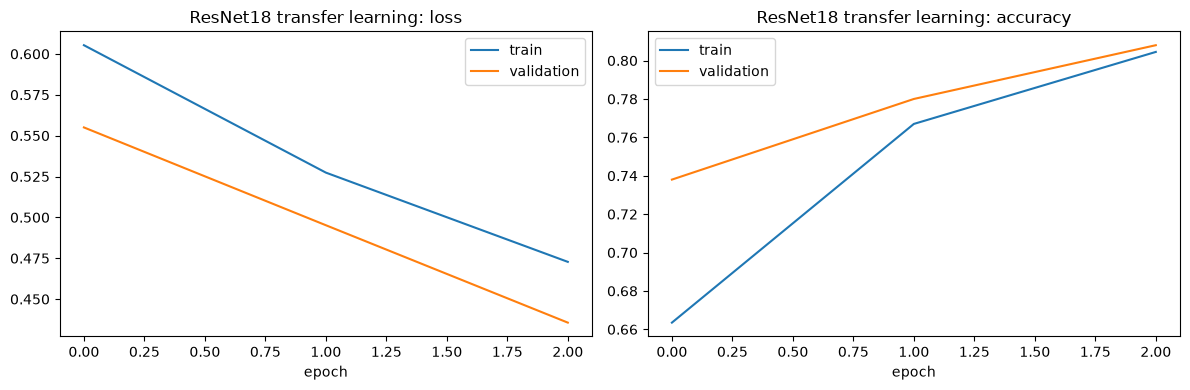

,test_loss,test_accuracy,threshold
VGG16,0.078671,0.964,0.50
ResNet18,0.421726,0.848,0.50
Custom CNN,0.416996,0.806,0.47


In [6]:
def make_resnet():
    model = models.resnet18(weights = models.ResNet18_Weights.DEFAULT)
    for parameter in model.parameters():
        parameter.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, 1)
    return model


resnet_model, resnet_history = fit(make_resnet(), epochs=3, lr=1e-4)
resnet_score = evaluate_model(resnet_model)
plot_history(resnet_history, "ResNet18 transfer learning")
scores = pd.DataFrame(
    [cnn_score, vgg_score, resnet_score],
    index=["Custom CNN", "VGG16", "ResNet18"],
).sort_values("test_accuracy", ascending=False)
scores

## 5. Inference on a custom image

In [7]:
def predict_image(image_path, model = resnet_model):
    image = Image.open(image_path).convert("RGB")
    tensor = eval_transform(image).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        probability = torch.sigmoid(model(tensor).squeeze()).item()
    label="dog" if probability>=0.5 else "cat"
    return pd.DataFrame([{
        "image": str(image_path), "prediction": label, "dog_probability": probability}])

# Example predictions from the held-out test subset using the best model (VGG16).

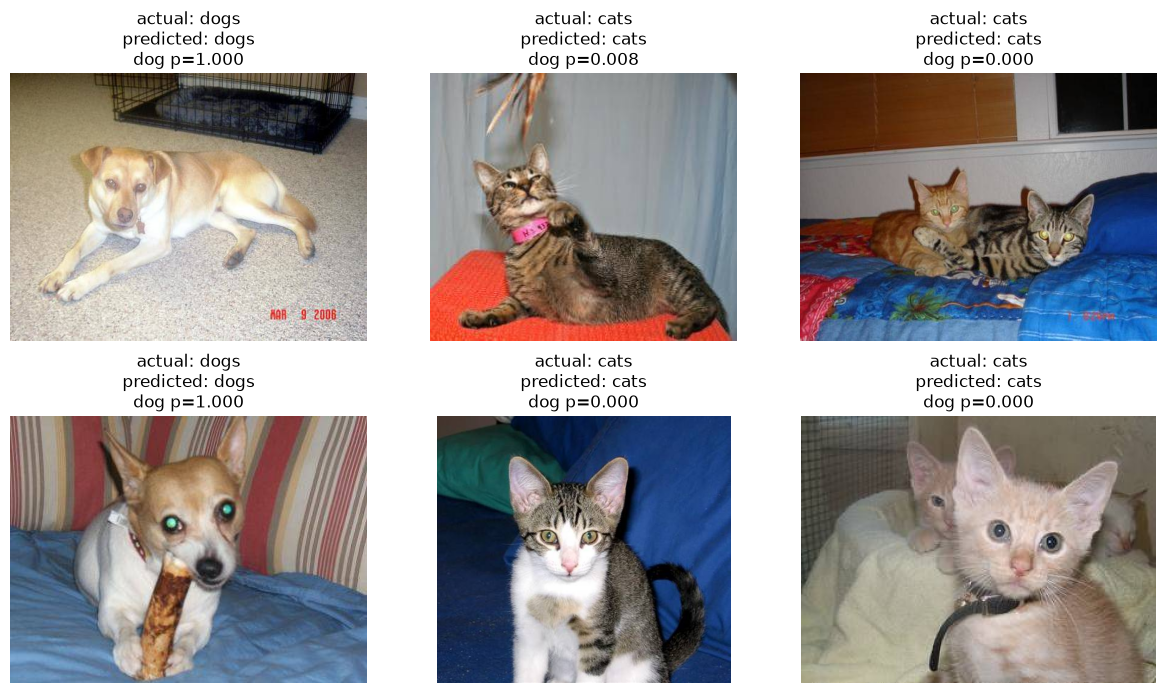

,file,actual,prediction,dog_probability,correct
0,dog.2424.jpg,dogs,dogs,0.999990,True
1,cat.2383.jpg,cats,cats,0.008367,True
2,cat.2145.jpg,cats,cats,0.000006,True
3,dog.2165.jpg,dogs,dogs,1.000000,True
4,cat.2477.jpg,cats,cats,0.000003,True
5,cat.2023.jpg,cats,cats,0.000128,True


In [8]:
rng = np.random.default_rng(SEED)
example_indices = rng.choice(len(test_ds), size=min(6, len(test_ds)), replace=False)
prediction_rows = []
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, local_index in zip(axes.ravel(), example_indices):
    dataset_index = test_ds.indices[local_index]
    image_path, target_index = holdout.samples[dataset_index]
    image = Image.open(image_path).convert('RGB')
    tensor = eval_transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        dog_probability = torch.sigmoid(vgg_model(tensor).squeeze()).item()
    prediction = train_ds.classes[int(dog_probability >= 0.5)]
    actual = train_ds.classes[target_index]
    prediction_rows.append({'file': Path(image_path).name, 'actual': actual, 'prediction': prediction, 'dog_probability': dog_probability, 'correct': actual == prediction})
    ax.imshow(image); ax.set_title(f'actual: {actual}\npredicted: {prediction}\ndog p={dog_probability:.3f}')
    ax.axis('off')
for ax in axes.ravel()[len(example_indices):]: ax.axis('off')
plt.tight_layout(); plt.show()
example_predictions = pd.DataFrame(prediction_rows)
example_predictions

## Conclusion

The custom CNN satisfies the three-convolutional-layer requirement. VGG16 and ResNet18 use frozen ImageNet features with a new binary classification head. The final comparison is based on the held-out test subset, while the validation subset is used for model selection.